In [205]:
### --- PLOTTING TOOLS --- ###

import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.axes import Axes
from matplotlib.patches import Ellipse
import numpy as np

# Plotting tools

def plot_points(centroids, ax: Axes, color='red', marker='o'):
    ax.scatter(centroids[:,0], centroids[:,1], s=4, marker=marker, c=color)

def plot_evaluation_points(points, ax: Axes, color='black', marker='o'):
    ax.scatter(points[:,0], points[:,1], s=20, marker=marker, c=color)

    # Also plot visual labels (letters) for each point
    shift = 0.02
    import string
    letters = list(string.ascii_uppercase)

    for j in range(len(points)):
        x = points[j,0] + shift
        y = points[j,1] + shift
        ax.text(x, y, letters[j], horizontalalignment='left')

def plot_ellipses(
        ellipses,
        ax: Axes,
        plot_numbers=False
    ):
    for j, ellipse in enumerate(ellipses):
        ax.add_patch(ellipse)

    # Plot ellipse numbers
    if plot_numbers:
        shift = 0.02
        for j in range(len(ellipses)):
            xy = ellipses[j].get_center()
            x = xy[0] + shift
            y = xy[1] + shift
            ax.text(x, y, f'{j+1}', horizontalalignment='left')

def convert_to_ellipse_object(
        Q: np.array,
        centroid: np.array,
        color = 'red',
        alpha = 0.3,
    ):

    D, U = np.linalg.eigh(Q)
    # Length of axes are lambda_i^{-0.5}.
    # So total diameter is 2 / D**(1/2).
    lengths = 2 * (D ** (-0.5))
    width = lengths[0]
    height = lengths[1]
    # Angle is given by the rotation matrix U.
    # In particular, the first singular vector (which corresponds to the width)
    angle = np.rad2deg(np.arctan(U[0,1] / U[0,0]))
    return Ellipse(
        xy=centroid,
        width=width,
        height=height,
        angle=angle,
        color=color,
        alpha=alpha,
    )

mpl.rcParams.update(mpl.rcParamsDefault)


In [206]:
### --- DEFAULT PLOT SETTINGS --- ###

mpl.rcParams.update({
    # --- Figure ---
    "figure.figsize": (3.4, 2.4),   # good for single-column papers
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,

    # --- Fonts ---
    "font.size": 7,
    "axes.titlesize": 6,
    "axes.labelsize": 6,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,

    # Use LaTeX-like serif fonts (great for papers)
    "font.family": "serif",
    # "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    # "mathtext.fontset": "dejavuserif",

    # --- Axes ---
    "axes.linewidth": 0.8,
    "axes.grid": False,
    "axes.spines.top": False,
    "axes.spines.right": False,

    # --- Ticks ---
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.minor.size": 1.5,
    "ytick.minor.size": 1.5,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,

    # --- Lines ---
    "lines.linewidth": 1.5,
    "lines.markersize": 2,

    # --- Legend ---
    "legend.frameon": False,

    # --- PDF/Vector friendliness ---
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


In [207]:
### --- CLUSTER TOOLS --- ###

from scipy.spatial import ConvexHull

# Each of the following sampling functions are centered at origin and are based on unit ball
# In other words, no ellipses
def generate_unit_ball_points_uniform(N, d=2):
    directions = np.random.randn(N, d)
    directions /= np.linalg.norm(directions, axis=1)[:,None]
    radii = np.random.random(N) ** (1/d)
    return (directions * radii[:,None])

def generate_unit_ball_points_boundary_uniform(N, d=2):
    directions = np.random.randn(N, d)
    directions /= np.linalg.norm(directions, axis=1)[:,None]
    return directions

def generate_random_polytope(V, N, d=2):

    # Generate vertices and candidate points
    candidates = generate_unit_ball_points_uniform(N, d)
    polytope_vertices = generate_unit_ball_points_boundary_uniform(V, d)

    # Build convex hull
    convex_hull = ConvexHull(polytope_vertices)
    equations = convex_hull.equations
    A = equations[:,:-1]
    b = equations[:,-1]

    # Test candidates: a point is in if Ax + b < 0.
    in_half_plane = ((candidates @ A.T) + b) < 0
    in_conv_hull_msk = in_half_plane.all(axis=1)
    polytope_points = candidates[in_conv_hull_msk]
    return polytope_points

def matrix_sqrt(Q):
    D, U = np.linalg.eigh(Q)
    return (U * (np.abs(D) ** 0.5)) @ U.T


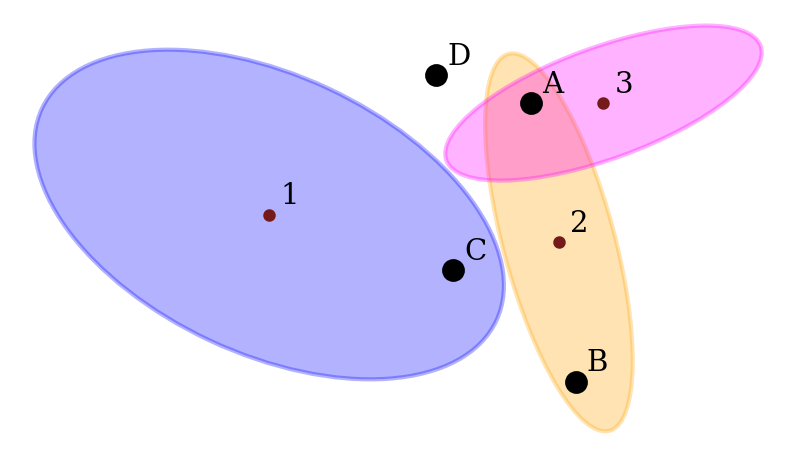

In [208]:
### --- FIGURE 1: Inference description --- ###

# Centroids and trust ellipses
centroids = np.array([
    [0.4, 0.6], # 1
    [0.92, 0.55], # 2
    [1.0, 0.8]  # 3
])
centroid_color = "#751A1A"
ellipse_colors = ['blue', 'orange', 'magenta']
trust_ellipses = [
    Ellipse(centroids[0], width=0.9, height=0.5, angle=-25,  alpha=0.3, color=ellipse_colors[0]),
    Ellipse(centroids[1], width=0.2, height=0.7, angle=15, alpha=0.3, color=ellipse_colors[1]),
    Ellipse(centroids[2], width=0.6, height=0.2, angle=20, alpha=0.3, color=ellipse_colors[2]),
]

# Example evaluation points
eval_points = np.array([
    [0.87, 0.8], # A
    [0.95, 0.3], # B
    [0.73, 0.5], # C
    [0.7, 0.85], # D
])
eval_color = 'black'

# Setting up first figure
fig1, ax1 = plt.subplots()
ax1.set_aspect('equal')
ax1.axis('off')

# Plot centroids and trust regions
plot_ellipses(trust_ellipses, ax1, plot_numbers=True)
plot_points(centroids, ax1, centroid_color, 'o')

# Plot evaluation points
plot_evaluation_points(eval_points, ax1, eval_color, 'o')
fig1.savefig('figs/inference_vis.png')

plt.show()

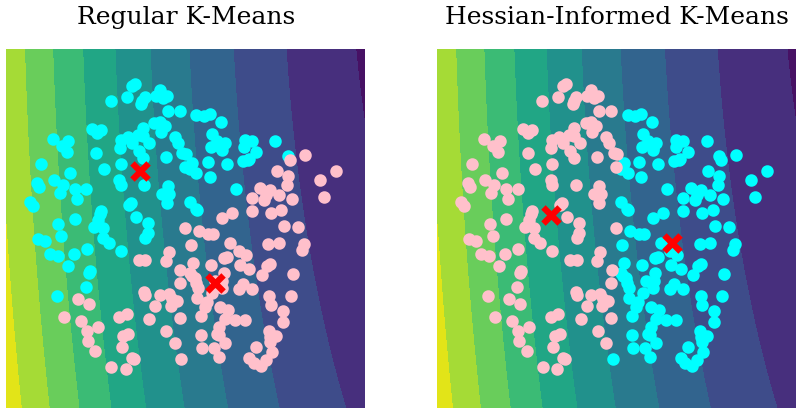

In [211]:
### --- FIGURE 2: Two-means clustering description --- ###
from src.problems.rosenbrock import rosenbrock, rosenbrock_grad, rosenbrock_hess

# Generate points in a cluster (convex region)
np.random.seed(6)
polytope_points = generate_random_polytope(8, 300)
# polytope_points = generate_unit_ball_points_uniform(250, d=2)
centroid = np.mean(polytope_points, axis=0)
centered_points = polytope_points - centroid

# Setting up second figure
fig2, ax2 = plt.subplots(1, 2)

# Underlying function for contours
s = 2
t = 2
def f(x, y):
    return 10 * (x-s) ** 2 + (y-t) ** 2
def grad_f(x, y):
    return np.column_stack((20 * (x-s), 2 * (y-t)))
def hess_f(x, y): # just takes a single point
    return np.array([
        [20, 0],
        [0, 2]
    ])
# def f(x, y):
#     return rosenbrock(np.column_stack((x,y)))
# def grad_f(x, y):
#     return rosenbrock_grad(np.column_stack((x,y)))
# def hess_f(x, y): # just takes a single point
#     return rosenbrock_hess(np.column_stack((x,y)))
x = np.linspace(-1.1, 1.1, 400)
X, Y = np.meshgrid(x, x)
Z = f(X, Y)

# Recluster the points

# A. K-Means (First eigenvector of covariance matrix, entire function)
_, _, V = np.linalg.svd(centered_points)
assign_msk_A = (centered_points @ V[0]) > 0
centroid_1A = np.mean(polytope_points[assign_msk_A], axis=0)
centroid_2A = np.mean(polytope_points[~assign_msk_A], axis=0)

# B. K-Means with fewer points (first evec of small covariance matrix)
# first compute error of points
f_centroid = f(centroid[0], centroid[1]).flatten()
g_centroid = grad_f(centroid[0], centroid[1]).flatten()
dx = polytope_points - centroid
linear_approx = f_centroid + dx @ g_centroid
exact = f(polytope_points[:,0], polytope_points[:,1]).flatten()
errors = np.abs(linear_approx - exact)
eps = 4
error_msk = errors < eps
# now compute covariance of the smaller matrix
centered_points_good_err = centered_points[error_msk]
_, _, V = np.linalg.svd(centered_points_good_err)
assign_msk_B = (polytope_points @ V[0]) > 0
centroid_1B = np.mean(polytope_points[assign_msk_B], axis=0)
centroid_2B = np.mean(polytope_points[~assign_msk_B], axis=0)

# C. Use Hessian
h_centroid = hess_f(centroid[0], centroid[1])
sqrt_h_centroid = matrix_sqrt(h_centroid).reshape(2,2)
_, _, V = np.linalg.svd(centered_points @ sqrt_h_centroid)
assign_msk_C = (polytope_points @ V[0]) > 0
centroid_1C = np.mean(polytope_points[assign_msk_C], axis=0)
centroid_2C = np.mean(polytope_points[~assign_msk_C], axis=0)

# Plot the contours for each plot
for ax in ax2:
    ax.set_aspect('equal', adjustable='box')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    ax.contourf(X, Y, Z, levels=10, cmap='viridis')


# Plot the points and other settings
c1 = 'cyan'
c2 = 'pink'

# Plot A
plot_points(polytope_points[assign_msk_A],  ax2[0], c1, 'o')
plot_points(polytope_points[~assign_msk_A], ax2[0], c2, 'o')
ax2[0].axis('off')
ax2[0].set_title('Regular K-Means')
ax2[0].scatter(centroid_1A[0], centroid_1A[1], c='red', marker='x', s=15)
ax2[0].scatter(centroid_2A[0], centroid_2A[1], c='red', marker='x', s=15)
# Plot B
# plot_points(polytope_points[assign_msk_B],  ax2[1], c1, 'o')
# plot_points(polytope_points[~assign_msk_B], ax2[1], c2, 'o')
# Plot C
plot_points(polytope_points[assign_msk_C],  ax2[1], c1, 'o')
plot_points(polytope_points[~assign_msk_C], ax2[1], c2, 'o')
ax2[1].axis('off')
ax2[1].set_title('Hessian-Informed K-Means')
ax2[1].scatter(centroid_1C[0], centroid_1C[1], c='red', marker='x', s=15)
ax2[1].scatter(centroid_2C[0], centroid_2C[1], c='red', marker='x', s=15)

plt.show()
fig2.savefig('hessian_kmeans.png')


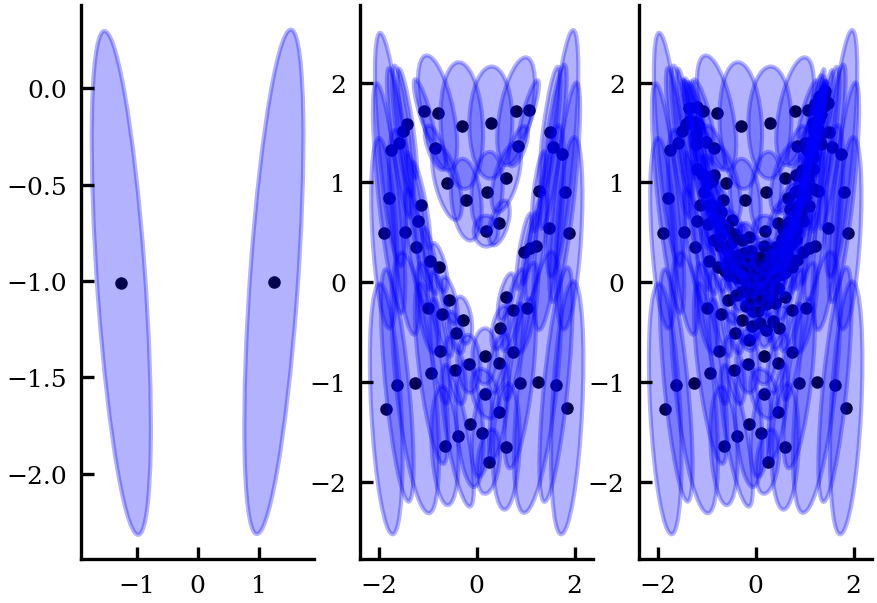

In [210]:
### --- FIGURE 3: Level by level for each function --- ###

from src.surrogate import HATANNSurrogate
from src.problems.rosenbrock import rosenbrock, rosenbrock_grad

# Training data
d = 2
N = 100000
X_train = np.random.uniform(-2, 2, (N, d))

# Adaptive clustering parameters
N_init_clusters = 4
levels = [3, 7, 50]
tol = 0.1

surrogates = [HATANNSurrogate(version='v2') for _ in range(len(levels))]

# plots
fig, ax = plt.subplots(1, 3)

# Train surrogates
for i in range(len(levels)):

    surrogates[i].train(
        X_train=X_train,
        f_fn=rosenbrock,
        g_fn=rosenbrock_grad,
        TOL=tol,
        ERROR_METRIC='Linf-local',
        NUM_INITIAL_CLUSTERS=N_init_clusters,
        SEED=0,
        MAX_LEVELS=levels[i]
    )

    centroids = surrogates[i].get_source_centroids()
    trust_ellipses = surrogates[i].get_trust_regions()
    ellipses = []
    for j, trust_ellipse in enumerate(trust_ellipses):
        ellipses.append(convert_to_ellipse_object(trust_ellipse, centroids[j], 'blue'))

    plot_points(centroids, ax[i], 'black', 'o')
    plot_ellipses(ellipses, ax[i], )


plt.show()
